### 다중분류

- 손글씨 분류   
  - total : 70000개
  - 학습set : 60000개
  - test set : 10000개
  - image shape : 28x28
  - class 10개 : 0~9











In [1]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import os
os.makedirs('results', exist_ok=True)

In [2]:
# 내 구글드라이브와 연동
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 장치 선택
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cuda


In [4]:
# 데이터 저장하기
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root = '/content/drive/MyDrive/Colab Notebooks/data'
                        , train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root = '/content/drive/MyDrive/Colab Notebooks/data'
                        , train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.98MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 134kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.42MB/s]


In [6]:
print(train_DS)
print(test_DS)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Test
    StandardTransform
Transform: ToTensor()


In [7]:
train_DS.classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [8]:
train_DS.class_to_idx

{'0 - zero': 0,
 '1 - one': 1,
 '2 - two': 2,
 '3 - three': 3,
 '4 - four': 4,
 '5 - five': 5,
 '6 - six': 6,
 '7 - seven': 7,
 '8 - eight': 8,
 '9 - nine': 9}

In [9]:
train_DS.data.shape

torch.Size([60000, 28, 28])

In [10]:
train_DS.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

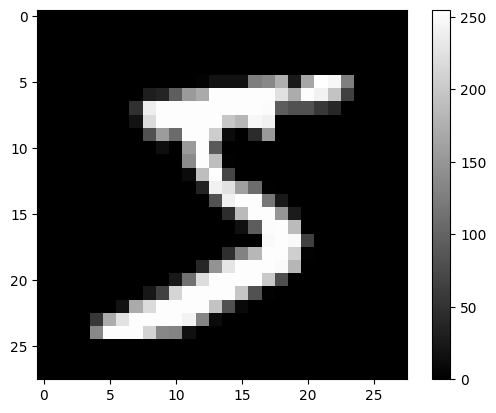

In [17]:
plt.imshow(train_DS.data[0], cmap='gray')
plt.colorbar()

In [16]:
print(train_DS.targets)
print(train_DS.targets.shape)

tensor([5, 0, 4,  ..., 5, 6, 8])
torch.Size([60000])


### DataLoader

In [19]:
BATCH_SIZE = 32
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

In [34]:
x_batch, y_batch = next(iter(train_DL))

# 원본데이터
print(type(train_DS.data))
print(train_DS.data.shape)
print(train_DS.data.dtype)
print(train_DS.data[0].shape)

# batch데이터
print(type(x_batch))
print(x_batch.shape)
print(x_batch.dtype)
print(x_batch[0].shape)

<class 'torch.Tensor'>
torch.Size([60000, 28, 28])
torch.uint8
torch.Size([28, 28])
<class 'torch.Tensor'>
torch.Size([32, 1, 28, 28])
torch.float32
torch.Size([1, 28, 28])


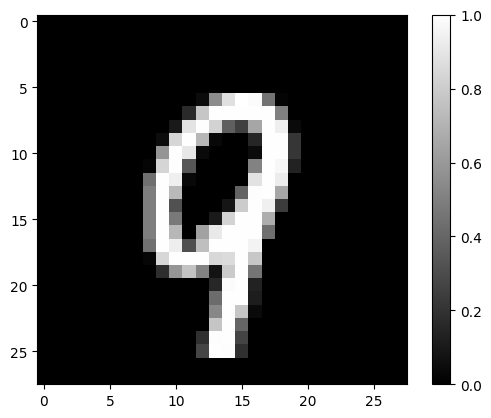

In [35]:
plt.imshow(x_batch[0].permute(1,2,0), cmap='gray')
plt.colorbar()

### Model 만들기

In [40]:
from torch import nn

class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 100),
                                nn.ReLU(),
                                nn.Linear(100, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [39]:
x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

flat_images = torch.flatten(x_batch)
print(flat_images.shape)

flat_images2 = torch.flatten(x_batch, start_dim=1)
print(flat_images2.shape)

torch.Size([32, 1, 28, 28])
torch.Size([25088])
torch.Size([32, 784])


In [43]:
model = MLP().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

model.eval()
with torch.no_grad():
  print(model(x_batch.to(DEVICE)).shape)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)
torch.Size([32, 1, 28, 28])
torch.Size([32, 10])


In [44]:
from torch import optim

LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

loss_history=[]
NoT = len(train_DL.dataset)

model.train()
for ep in range(EPOCH):
  rloss = 0
  for x_batch, y_batch in train_DL:
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)

    y_hat = model(x_batch)

    loss = criterion(y_hat, y_batch)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_b = loss.item() * x_batch.shape[0]
    rloss += loss_b

  loss_e = rloss/ NoT
  loss_history += [loss_e]
  print(f'Epoch : {ep+1}, train loss : {loss_e:.3f}')
  print('-' * 20)


Epoch : 1, train loss : 0.311
--------------------
Epoch : 2, train loss : 0.137
--------------------
Epoch : 3, train loss : 0.094
--------------------
Epoch : 4, train loss : 0.070
--------------------
Epoch : 5, train loss : 0.055
--------------------


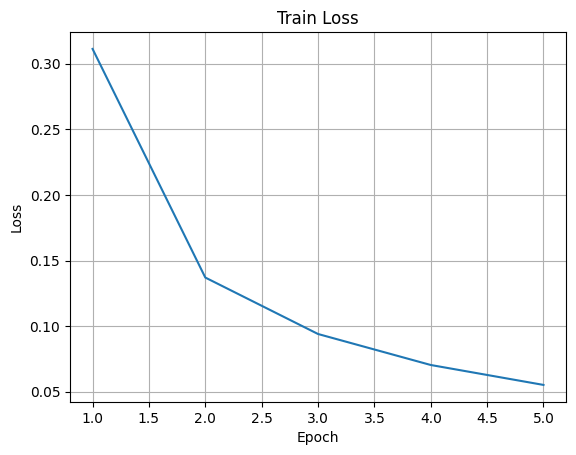

In [45]:
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss')
plt.grid()